# Line Chart (Avg User Retention Curve)

## Исходные данные для построения

Как сохранить: `user_retention.to_pickle("user_retention.pkl")`

In [32]:
user_retention = pd.read_pickle("user_retention.pkl")

user_retention

cohort_index,0,1,2,3,4,5,6,7,8,9,10
cohort_month,,,,,,,,,,,
2021-07,1.0,0.333876,0.345277,0.317590,0.328990,0.294788,0.280130,0.289902,0.270358,0.254072,0.239414
2021-08,1.0,0.284257,0.298834,0.253644,0.252187,0.233236,0.214286,0.204082,0.202624,0.172012,NaN
2021-09,1.0,0.301435,0.244019,0.223285,0.247209,0.186603,0.204147,0.189793,0.178628,NaN,NaN
2021-10,1.0,0.245115,0.266430,0.227353,0.202487,0.181172,0.179396,0.158082,NaN,NaN,NaN
2021-11,1.0,0.275100,0.204819,0.222892,0.198795,0.174699,0.176707,NaN,NaN,NaN,NaN
2021-12,1.0,0.190570,0.200393,0.161100,0.155206,0.149312,NaN,NaN,NaN,NaN,NaN
2022-01,1.0,0.218341,0.216157,0.189956,0.170306,NaN,NaN,NaN,NaN,NaN,NaN
2022-02,1.0,0.288557,0.154229,0.191542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-03,1.0,0.210648,0.175926,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Код для построения

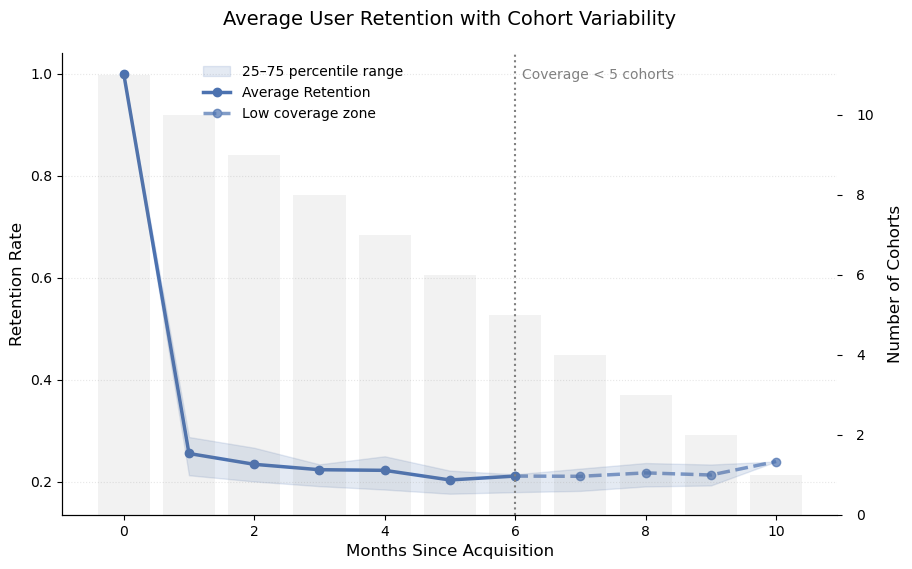

In [33]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# LOAD DATA
# =====================================================

#user_retention = pd.read_pickle("user_retention.pkl")
user_retention = pd.read_parquet("user_retention.parquet")

# =====================================================
# PREPARE DATA
# =====================================================

# Среднее
avg_user_retention = user_retention.mean(axis=0)

# Количество когорт
cohort_counts = user_retention.count(axis=0)

# Межквартильный диапазон
user_retention_q25 = user_retention.quantile(0.25, axis=0)
user_retention_q75 = user_retention.quantile(0.75, axis=0)

# Порог надежности
min_cohorts = 5

reliable_months = cohort_counts[cohort_counts >= min_cohorts].index
unreliable_months = cohort_counts[cohort_counts < min_cohorts].index

# Последний надежный месяц
cutoff = reliable_months.max()

# =====================================================
# AVG USER RETENTION CURVE
# =====================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

# ------------------
# Основная ось
# ------------------

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# IQR band
ax1.fill_between(
    avg_user_retention.index,
    user_retention_q25,
    user_retention_q75,
    color='#4C72B0',
    alpha=0.15,
    label='25–75 percentile range'
)

# Надежная часть линии
ax1.plot(
    avg_user_retention.loc[:cutoff].index,
    avg_user_retention.loc[:cutoff].values,
    marker='o',
    color='#4C72B0',
    linewidth=2.5,
    label='Average Retention'
)

# Хвост пунктиром
if len(unreliable_months) > 0:
    ax1.plot(
        avg_user_retention.loc[cutoff:].index,
        avg_user_retention.loc[cutoff:].values,
        marker='o',
        color='#4C72B0',
        linewidth=2.5,
        linestyle='--',
        alpha=0.7,
        label='Low coverage zone'
    )

# Вертикальная граница надежности
ax1.axvline(
    cutoff,
    color='grey',
    linestyle=':',
    linewidth=1.5
)

ax1.text(
    cutoff + 0.1,
    avg_user_retention.max() * 0.99,
    'Coverage < 5 cohorts',
    fontsize=10,
    color='grey'
)

ax1.set_xlabel('Months Since Acquisition', fontsize=12)
ax1.set_ylabel('Retention Rate', fontsize=12)

# ------------------
# Вторая ось
# ------------------

ax2 = ax1.twinx()

ax2.spines['top'].set_visible(False)

ax2.bar(
    cohort_counts.index,
    cohort_counts.values,
    color='grey',
    alpha=0.10,
    zorder=0
)

ax2.set_ylabel(
    'Number of Cohorts',
    fontsize=12,
    labelpad=10
)

ax2.tick_params(pad=10)
ax2.spines['right'].set_visible(False)
# ------------------
# Оформление
# ------------------

plt.title(
    'Average User Retention with Cohort Variability',
    fontsize=14,
    pad = 20
)

ax1.grid(
    axis='y',
    linestyle=':',
    alpha=0.3
)

ax1.legend(frameon=False, loc='upper center',  bbox_to_anchor=(0.31, 1.0))

#plt.tight_layout()
# plt.savefig("avg_user_retention_curve.png", dpi=300, bbox_inches="tight")
plt.show()